# CENG313 – Introduction to Data Science: Assignment 1
## Exploratory Data Analysis (EDA) & Baseline Modeling
**Competition:** [CMI – Detect Behavior with Sensor Data](https://www.kaggle.com/competitions/cmi-detect-behavior-with-sensor-data)

---

## 1. Problem Definition
* **Task:** Multivariate Time-Series Classification. Using multi-modal wearable sensor data recorded from a wrist-worn device (3-axis accelerometer, quaternion rotation/orientation, thermopile temperature, and Time-of-Flight proximity sensors), the task is to classify specific hand/wrist gestures and distinguish **Body-Focused Repetitive Behaviors (BFRBs)** (e.g., hair pulling, skin pinching/scratching) from everyday non-BFRB activities.
* **Target Variable:** `gesture` (18 classes, one label per sequence). `sequence_type` shows if the gesture is a BFRB (Target) or not (Non-Target).
  * Note: `behavior` is not a target. It shows the phase of each row (e.g. moving the hand, performing the gesture).
* **Evaluation Metric:** The competition evaluates models using a **Hierarchical Macro F1** score, defined as the average of:
  1. Binary F1 score for BFRB vs. Non-BFRB classification.
  2. Macro F1 over 9 classes: the 8 BFRB gestures + one `non_target` class (all 10 non-BFRB gestures merged).

  In Section 5, we report both standard **Macro F1** and the competition's **Hierarchical Macro F1** (implemented in `src/utils.py`).

## 2. Data Overview
In this section, we load the primary training time-series dataset (`train.csv`) and participant metadata (`train_demographics.csv`) using our modular helper functions from `src/data.py`. We inspect dataset dimensions, data types, summary statistics, exact duplicates, and missing value patterns across sensor modalities.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import load_data

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams['figure.dpi'] = 110

# Load datasets via src/data.py
train, demo = load_data("data")

print(f"Train time-series shape:      {train.shape[0]:,} rows x {train.shape[1]} columns")
print(f"Demographics shape:           {demo.shape[0]:,} rows x {demo.shape[1]} columns")
print(f"Unique sequences (recordings): {train['sequence_id'].nunique():,}")
print(f"Unique participants (subjects):{train['subject'].nunique():,}")
print(f"Exact duplicate rows:         {train.duplicated().sum()}")

print("\n--- Column Data Types ---")
print(train.dtypes.value_counts())

Train time-series shape:      574,945 rows x 341 columns
Demographics shape:           81 rows x 8 columns
Unique sequences (recordings): 8,151
Unique participants (subjects):81
Exact duplicate rows:         0

--- Column Data Types ---
float64    332
str          8
int64        1
Name: count, dtype: int64


In [2]:
# Group sensor columns by modality
acc_cols = [c for c in train.columns if c.startswith('acc_')]
rot_cols = [c for c in train.columns if c.startswith('rot_')]
thm_cols = [c for c in train.columns if c.startswith('thm_')]
tof_cols = [c for c in train.columns if c.startswith('tof_')]

print(f"Sensor channel breakdown -> IMU Acc: {len(acc_cols)}, IMU Rot: {len(rot_cols)}, Thermopile: {len(thm_cols)}, ToF: {len(tof_cols)}")

print("\n--- Summary Statistics (IMU Accelerometer & Rotation) ---")
display(train[acc_cols + rot_cols].describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']].round(3))

print("\n--- Missing Values by Modality ---")
modality_missing = []
for name, cols in [('Accelerometer (acc_*)', acc_cols), ('Rotation (rot_*)', rot_cols), 
                   ('Thermopile (thm_*)', thm_cols), ('Time-of-Flight (tof_*)', tof_cols)]:
    if cols:
        pct = train[cols].isnull().mean().mean() * 100
        modality_missing.append({'Modality': name, 'Channel Count': len(cols), 'Avg Missing (%)': round(pct, 2)})
display(pd.DataFrame(modality_missing))

Sensor channel breakdown -> IMU Acc: 3, IMU Rot: 4, Thermopile: 5, ToF: 320

--- Summary Statistics (IMU Accelerometer & Rotation) ---


,count,mean,std,min,25%,50%,75%,max
acc_x,574945.0,1.640,5.781,-34.586,-2.965,2.973,6.344,46.328
acc_y,574945.0,1.791,5.004,-24.402,-2.121,0.695,6.816,27.184
acc_z,574945.0,-0.460,6.096,-42.855,-5.418,-1.562,5.164,30.078
rot_w,571253.0,0.360,0.226,0.000,0.180,0.340,0.503,0.999
rot_x,571253.0,-0.120,0.466,-0.999,-0.456,-0.187,0.205,1.000
rot_y,571253.0,-0.060,0.543,-1.000,-0.512,-0.113,0.440,0.999
rot_z,571253.0,-0.188,0.504,-0.998,-0.628,-0.264,0.251,1.000



--- Missing Values by Modality ---


,Modality,Channel Count,Avg Missing (%)
0,Accelerometer (acc_*),3,0.00
1,Rotation (rot_*),4,0.64
2,Thermopile (thm_*),5,2.11
3,Time-of-Flight (tof_*),320,1.91


### 2.1 Data Quality Checks
Before EDA we wanted to check if we can trust the data. We used the noise types from the lecture: label consistency, missing values, encoded values (`-1` in ToF), impossible values and the merge with the demographics table.

In [12]:
# 1) Label consistency: each sequence should have one gesture and one subject
per_seq = train.groupby('sequence_id')[['gesture', 'subject', 'sequence_type']].nunique()
print("Sequences with more than one label/subject:", (per_seq > 1).any(axis=1).sum())

# 2) Missing values: sequences with no thm / tof data at all
seq_has_thm = train[thm_cols].notnull().any(axis=1).groupby(train['sequence_id']).any()
seq_has_tof = train[tof_cols].notnull().any(axis=1).groupby(train['sequence_id']).any()
print(f"Sequences with no thm data: {(~seq_has_thm).sum()} / {len(seq_has_thm)}")
print(f"Sequences with no tof data: {(~seq_has_tof).sum()} / {len(seq_has_tof)}")
print("Rows with missing acc / rot:", train[acc_cols].isnull().any(axis=1).sum(), "/", train[rot_cols].isnull().any(axis=1).sum())

# 3) Encoded value: -1 in ToF means "no object detected"
tof_vals = train[tof_cols]
print(f"ToF -1 share: {(tof_vals == -1).mean().mean()*100:.1f}% | ToF NaN share: {tof_vals.isnull().mean().mean()*100:.1f}%")

# 4) Impossible values: quaternion length should be ~1, temperatures should be realistic
quat_norm = np.sqrt((train[rot_cols].dropna() ** 2).sum(axis=1))
print("Quaternion norm min / mean / max:", round(quat_norm.min(), 3), round(quat_norm.mean(), 3), round(quat_norm.max(), 3))
print("Thermopile min / max (C):", round(train[thm_cols].min().min(), 1), round(train[thm_cols].max().max(), 1))

# 5) Demographics + merge check
merged = train[['subject']].merge(demo, on='subject', how='left')
print("Rows before / after merge:", len(train), len(merged), "| rows without demographics:", merged['age'].isnull().sum())
demo_check = demo.assign(ratio=(demo['elbow_to_wrist_cm'] / demo['shoulder_to_wrist_cm']).round(2))
display(demo_check.sort_values('elbow_to_wrist_cm', ascending=False)[['subject', 'age', 'height_cm', 'shoulder_to_wrist_cm', 'elbow_to_wrist_cm', 'ratio']].head(3))

Sequences with more than one label/subject: 0
Sequences with no thm data: 96 / 8151
Sequences with no tof data: 96 / 8151
Rows with missing acc / rot: 0 / 3692
ToF -1 share: 57.5% | ToF NaN share: 1.9%
Quaternion norm min / mean / max: 1.0 1.0 1.0
Thermopile min / max (C): -0.4 39.6
Rows before / after merge: 574945 574945 | rows without demographics: 0


,subject,age,height_cm,shoulder_to_wrist_cm,elbow_to_wrist_cm,ratio
7,SUBJ_011323,30,175.0,71,44.0,0.62
44,SUBJ_039498,30,186.0,55,30.0,0.55
11,SUBJ_017170,53,190.5,60,29.0,0.48


**Data Overview Findings:**
* **Size and structure:** `train.csv` has 574,945 rows and 341 columns. These rows belong to 8,151 sequences from 81 subjects, so each sequence has many time steps. `train_demographics.csv` has one row per subject (81 rows). There are **0 duplicate rows**.
* **Labels are consistent:** Every sequence has only one `gesture`, one `subject` and one `sequence_type`, so we did not find contradictory labels.
* **Missing values:** IMU is almost complete (`acc_*` 0%, `rot_*` 0.64% of rows). Only **96 of 8,151 sequences (1.2%)** have no thermopile and no ToF data at all. This is important because in the test set about half of the sequences will be IMU-only, but in train almost all sequences have all sensors.
* **Encoded value in ToF:** 57.5% of all ToF values are `-1`, which means "no object detected", not a real distance. Real NaN is only 1.9%. So we should not treat `-1` like a normal number when we compute features.
* **Impossible / strange values:** Quaternion length is 1.0 for all rows, so rotation data looks correct. Thermopile values go from -0.4 °C to 39.6 °C. The upper value fits body temperature, but -0.4 °C is not realistic, so it is probably a sensor error. In demographics, one subject (`SUBJ_011323`) has the largest arm lengths (shoulder-to-wrist 71 cm, elbow-to-wrist 44 cm). It looks suspicious but not impossible, and demographics are not used in our baseline, so we keep it.
* **Merge check:** Joining demographics on `subject` keeps the row count the same (574,945) and every row gets demographic info.

## 3. Exploratory Data Analysis (EDA)
Because EDA accounts for the core analytical weight of Assignment 1, we conduct a thorough multi-angle investigation covering:
1. **Target Class Balance & BFRB vs. Non-BFRB Breakdown**
2. **Sequence Duration (Time-Step) Distributions & Outliers**
3. **Sensor Modality Availability Across Sequences (IMU-only vs. Full-Sensor)**
4. **Raw Time-Series Signal Dynamics (BFRB vs. Non-BFRB Accelerometer & Thermopile Traces)**
5. **Distribution & Outlier Analysis of Acceleration Magnitude Across Gestures**
6. **Inter-Sensor Correlation Structure**
7. **Participant Demographics & Subject-Level Recording Counts**

Every visualization is immediately followed by a written analytical interpretation.

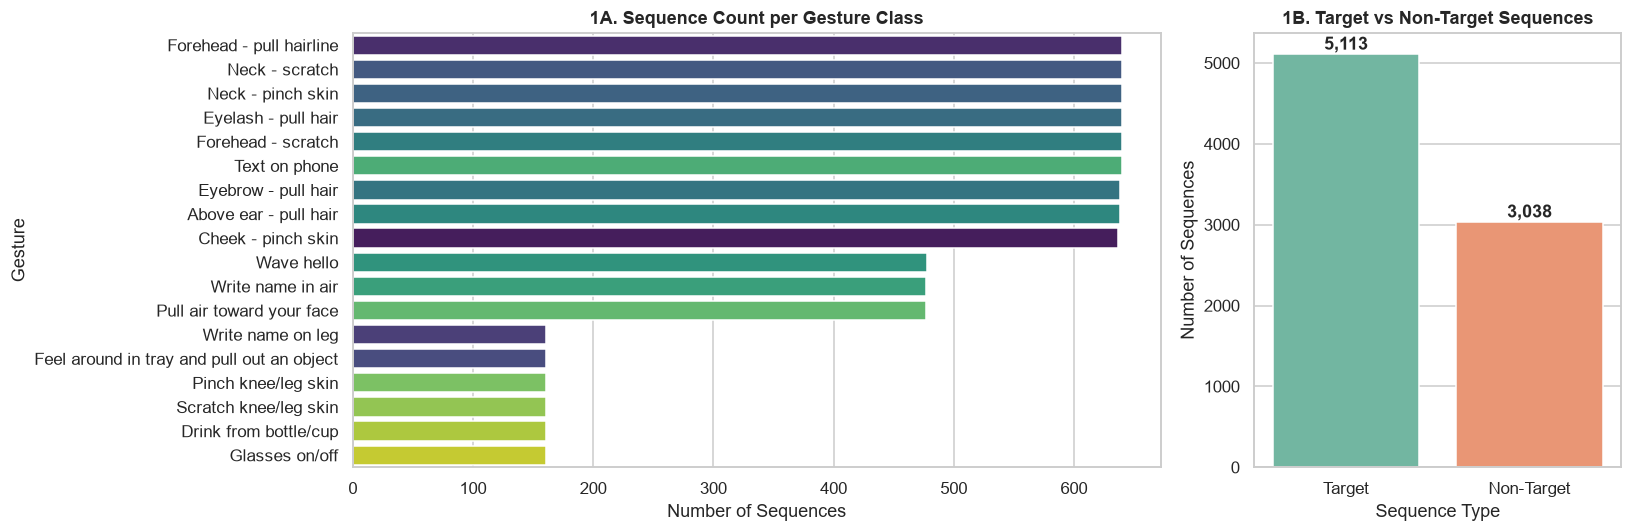

In [13]:
# Create sequence-level metadata table
seq_meta = train.drop_duplicates('sequence_id').copy()
seq_meta = pd.merge(seq_meta, demo, on='subject', how='left')

# --- PLOT 1: Target Class Balance ---
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [2.2, 1]})

gesture_order = seq_meta['gesture'].value_counts().index
sns.countplot(data=seq_meta, y='gesture', order=gesture_order, hue='gesture', palette='viridis', legend=False, ax=axes[0])
axes[0].set_title("1A. Sequence Count per Gesture Class", fontweight='bold')
axes[0].set_xlabel("Number of Sequences")
axes[0].set_ylabel("Gesture")

if 'sequence_type' in seq_meta.columns:
    beh_counts = seq_meta['sequence_type'].value_counts()
    sns.barplot(x=beh_counts.index, y=beh_counts.values, hue=beh_counts.index, palette='Set2', legend=False, ax=axes[1])
    axes[1].set_title("1B. Target vs Non-Target Sequences", fontweight='bold')
    axes[1].set_xlabel("Sequence Type")
    axes[1].set_ylabel("Number of Sequences")
    for i, v in enumerate(beh_counts.values):
        axes[1].text(i, v + max(beh_counts.values)*0.01, f"{v:,}", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

**Interpretation 1 (Target Class Balance):**
* **Target vs Non-Target:** 5,113 sequences (62.7%) are Target (BFRB) and 3,038 (37.3%) are Non-Target, so BFRB gestures are actually the majority.
* **Class imbalance between gestures:** All 8 BFRB gestures and *Text on phone* have about 640 sequences. Three non-target gestures (*Wave hello*, *Write name in air*, *Pull air toward your face*) have about 480, and the other six non-target gestures have only 161. So the largest class is about 4 times bigger than the smallest one.
* **Why this matters:** With this imbalance, accuracy could look good even if the model ignores small classes. Macro F1 gives every class the same weight, so small classes also count.

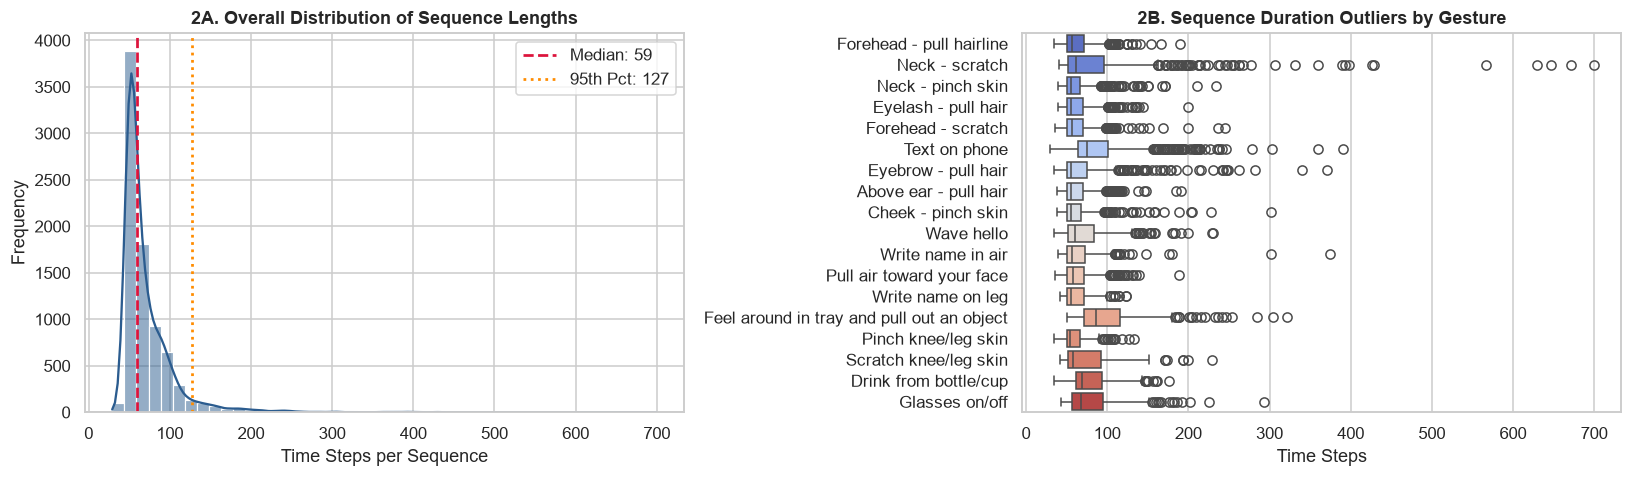

Sequence length summary -> Min: 29, Median: 59, Mean: 70.5, Max: 700


In [4]:
# --- PLOT 2: Sequence Length Distribution & Outliers ---
seq_lengths = train.groupby('sequence_id').size().rename('seq_len')
seq_meta_len = seq_meta.merge(seq_lengths, on='sequence_id')

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

sns.histplot(seq_lengths, bins=45, kde=True, color='#2b5c8f', ax=axes[0])
axes[0].axvline(seq_lengths.median(), color='crimson', linestyle='--', linewidth=1.8, label=f"Median: {seq_lengths.median():.0f}")
axes[0].axvline(seq_lengths.quantile(0.95), color='darkorange', linestyle=':', linewidth=1.8, label=f"95th Pct: {seq_lengths.quantile(0.95):.0f}")
axes[0].set_title("2A. Overall Distribution of Sequence Lengths", fontweight='bold')
axes[0].set_xlabel("Time Steps per Sequence")
axes[0].set_ylabel("Frequency")
axes[0].legend()

sns.boxplot(data=seq_meta_len, x='seq_len', y='gesture', order=gesture_order, palette='coolwarm', ax=axes[1])
axes[1].set_title("2B. Sequence Duration Outliers by Gesture", fontweight='bold')
axes[1].set_xlabel("Time Steps")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

print(f"Sequence length summary -> Min: {seq_lengths.min()}, Median: {seq_lengths.median():.0f}, Mean: {seq_lengths.mean():.1f}, Max: {seq_lengths.max()}")

**Interpretation 2 (Sequence Lengths & Temporal Outliers):**
* **Right-Skewed Duration:** Most gesture sequences cluster tightly around the median duration, while a long right tail extends past the 95th percentile.
* **Modeling Implication:** Because raw sequences vary substantially in length, sequence models require padding/truncation, whereas tabular baselines require **length-invariant statistical aggregations** (`mean`, `std`, quantiles) per `sequence_id` so longer recordings do not bias feature magnitudes.

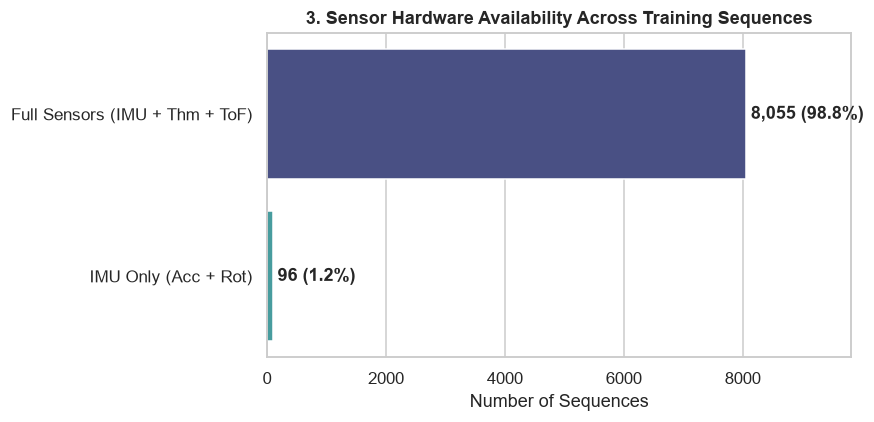

In [5]:
# --- PLOT 3: Sensor Modality Availability (IMU-only vs Full-Sensor Sequences) ---
seq_missing = train.groupby('sequence_id').apply(
    lambda g: pd.Series({
        'has_thm': g[thm_cols].notnull().any().any() if thm_cols else False,
        'has_tof': g[tof_cols].notnull().any().any() if tof_cols else False
    })
)
seq_missing['Sensor Configuration'] = np.where(
    seq_missing['has_thm'] & seq_missing['has_tof'], 'Full Sensors (IMU + Thm + ToF)',
    np.where(~seq_missing['has_thm'] & ~seq_missing['has_tof'], 'IMU Only (Acc + Rot)', 'Partial Peripheral Sensors')
)

plt.figure(figsize=(8, 4))
cfg_counts = seq_missing['Sensor Configuration'].value_counts()
sns.barplot(x=cfg_counts.values, y=cfg_counts.index, hue=cfg_counts.index, palette='mako', legend=False)
plt.title("3. Sensor Hardware Availability Across Training Sequences", fontweight='bold')
plt.xlabel("Number of Sequences")
plt.ylabel("")
for i, v in enumerate(cfg_counts.values):
    plt.text(v + max(cfg_counts.values)*0.01, i, f"{v:,} ({v/len(seq_missing)*100:.1f}%)", va='center', fontweight='bold')
plt.xlim(0, max(cfg_counts.values)*1.22)
plt.tight_layout()
plt.show()

**Interpretation 3 (Sensor Modality Availability):**
* **Almost all training sequences have all sensors:** 8,055 sequences (98.8%) have IMU + thermopile + ToF, and only **96 sequences (1.2%)** are IMU-only. There is no "partial" group, so when thermopile data is missing, ToF data is also missing (and the other way around).
* **Difference from the test set:** In the hidden test set about **half** of the sequences are IMU-only. So the model sees very few IMU-only examples during training, and a model that depends too much on `thm_*` / `tof_*` may do worse on the test set.
* **Design decision:** We keep these 96 sequences and fill their missing sensor features instead of dropping them, so the pipeline also works for IMU-only recordings.

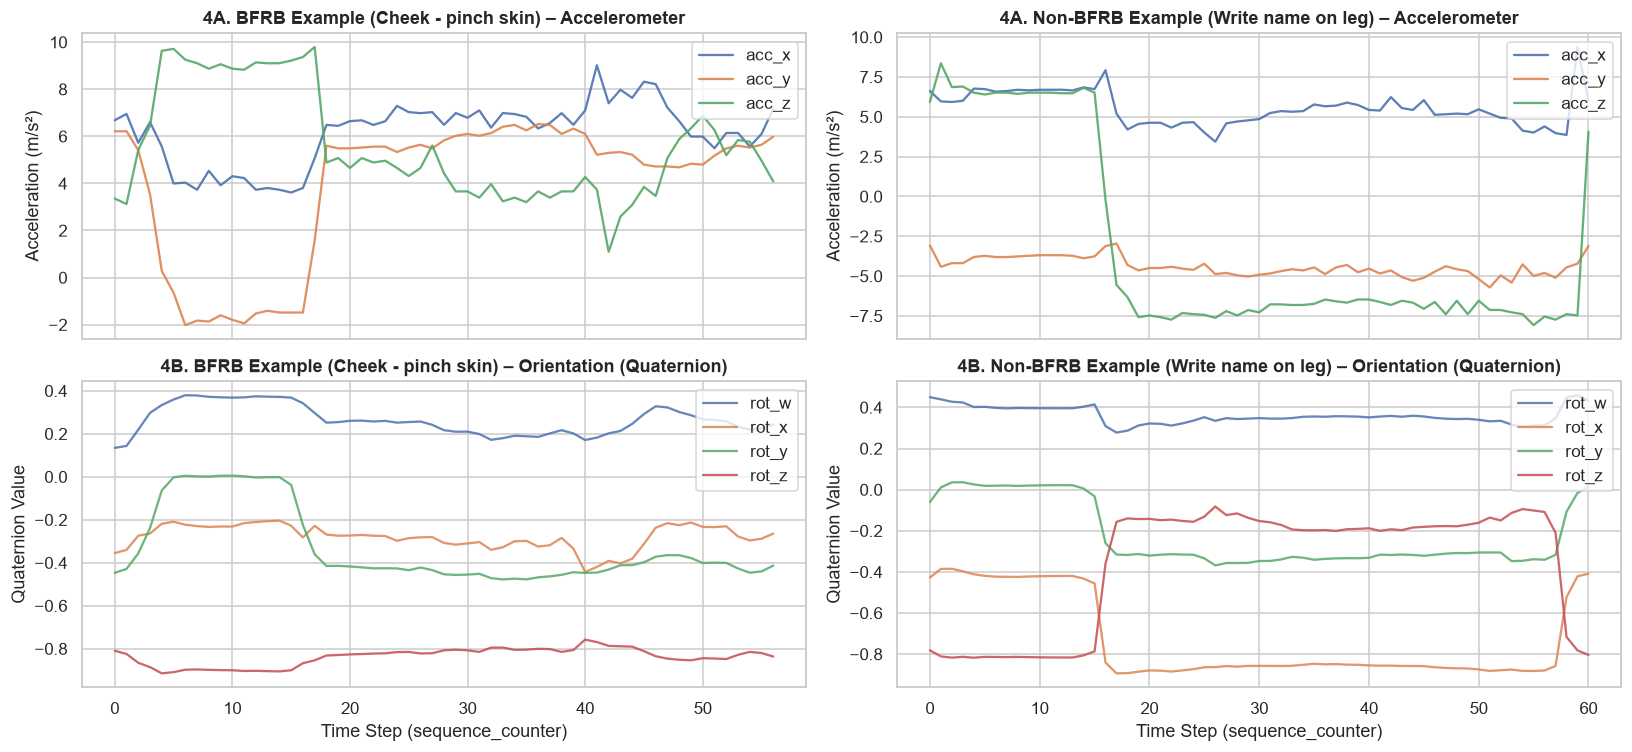

In [14]:
# --- PLOT 4: Raw Time-Series Dynamics (BFRB vs Non-BFRB Signal Comparison) ---
bfrb_candidates = seq_meta[seq_meta['sequence_type'] == 'Target']
non_bfrb_candidates = seq_meta[seq_meta['sequence_type'] == 'Non-Target']

seq_bfrb = bfrb_candidates['sequence_id'].iloc[0] if len(bfrb_candidates) > 0 else seq_meta['sequence_id'].iloc[0]
seq_ctrl = non_bfrb_candidates['sequence_id'].iloc[0] if len(non_bfrb_candidates) > 0 else seq_meta['sequence_id'].iloc[1]

fig, axes = plt.subplots(2, 2, figsize=(15, 7), sharex='col')

for col_idx, (sid, label_prefix) in enumerate([(seq_bfrb, 'BFRB Example'), (seq_ctrl, 'Non-BFRB Example')]):
    sub = train[train['sequence_id'] == sid].sort_values('sequence_counter')
    g_name = sub['gesture'].iloc[0]
    
    # Top row: 3-Axis Accelerometer
    axes[0, col_idx].plot(sub['sequence_counter'], sub['acc_x'], label='acc_x', alpha=0.9)
    axes[0, col_idx].plot(sub['sequence_counter'], sub['acc_y'], label='acc_y', alpha=0.9)
    axes[0, col_idx].plot(sub['sequence_counter'], sub['acc_z'], label='acc_z', alpha=0.9)
    axes[0, col_idx].set_title(f"4A. {label_prefix} ({g_name}) – Accelerometer", fontweight='bold')
    axes[0, col_idx].set_ylabel("Acceleration (m/s²)")
    axes[0, col_idx].legend(loc='upper right')
    
    # Bottom row: Quaternion Rotation
    for r_col in rot_cols:
        axes[1, col_idx].plot(sub['sequence_counter'], sub[r_col], label=r_col, alpha=0.85)
    axes[1, col_idx].set_title(f"4B. {label_prefix} ({g_name}) – Orientation (Quaternion)", fontweight='bold')
    axes[1, col_idx].set_xlabel("Time Step (sequence_counter)")
    axes[1, col_idx].set_ylabel("Quaternion Value")
    axes[1, col_idx].legend(loc='upper right')

plt.tight_layout()
plt.show()

**Interpretation 4 (Raw Sensor Signals):**
* We picked one BFRB sequence (`Cheek - pinch skin`) and one non-BFRB sequence (`Write name on leg`). Both are about 55-60 time steps long.
* In both examples there is a clear jump around time step 15-17. This is the moment the hand reaches the target location, and the orientation (`rot_*`) and gravity direction (`acc_*`) change suddenly. After that the signals stay more stable while the gesture is performed.
* The main difference is the direction of the hand. In `Write name on leg`, `acc_z` goes from about +6.5 to about -7.5 m/s², so the wrist turns toward the leg. In `Cheek - pinch skin`, the values stay in a different range, because the hand is near the face.
* So the **mean** of each channel (where the hand is) and the **std** (how much it moves) look useful as features. But this is only one example per class, so we cannot generalize from it alone.

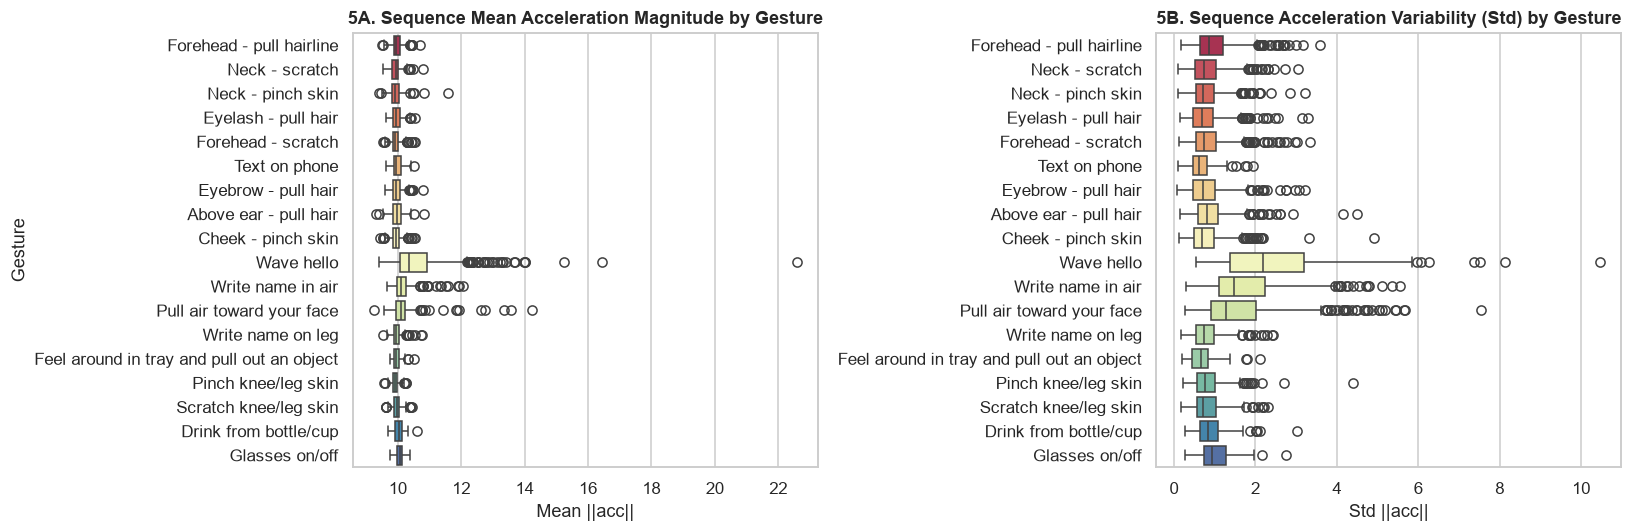

In [7]:
# --- PLOT 5: Acceleration Magnitude Distribution & Outliers by Gesture ---
train['acc_mag'] = np.sqrt(train['acc_x']**2 + train['acc_y']**2 + train['acc_z']**2)
seq_acc_stats = train.groupby(['sequence_id', 'gesture'])['acc_mag'].agg(['mean', 'std']).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=seq_acc_stats, x='mean', y='gesture', order=gesture_order, palette='Spectral', ax=axes[0])
axes[0].set_title("5A. Sequence Mean Acceleration Magnitude by Gesture", fontweight='bold')
axes[0].set_xlabel("Mean ||acc||")
axes[0].set_ylabel("Gesture")

sns.boxplot(data=seq_acc_stats, x='std', y='gesture', order=gesture_order, palette='Spectral', ax=axes[1])
axes[1].set_title("5B. Sequence Acceleration Variability (Std) by Gesture", fontweight='bold')
axes[1].set_xlabel("Std ||acc||")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

# Drop temporary helper column from train
train.drop(columns=['acc_mag'], inplace=True)

**Interpretation 5 (Acceleration Magnitude Distributions & Outliers):**
* **Separability Across Classes:** High-energy gestures display substantially higher acceleration variability (`Std ||acc||`) and upper-tail outliers than stationary or subtle BFRB movements.
* **Outlier Robustness:** Several gesture classes contain extreme upper outliers in `Std ||acc||` (likely caused by rapid arm transitions before/after the target gesture). Tree-based models like Random Forest handle these heavy-tailed distributions naturally without distortion.

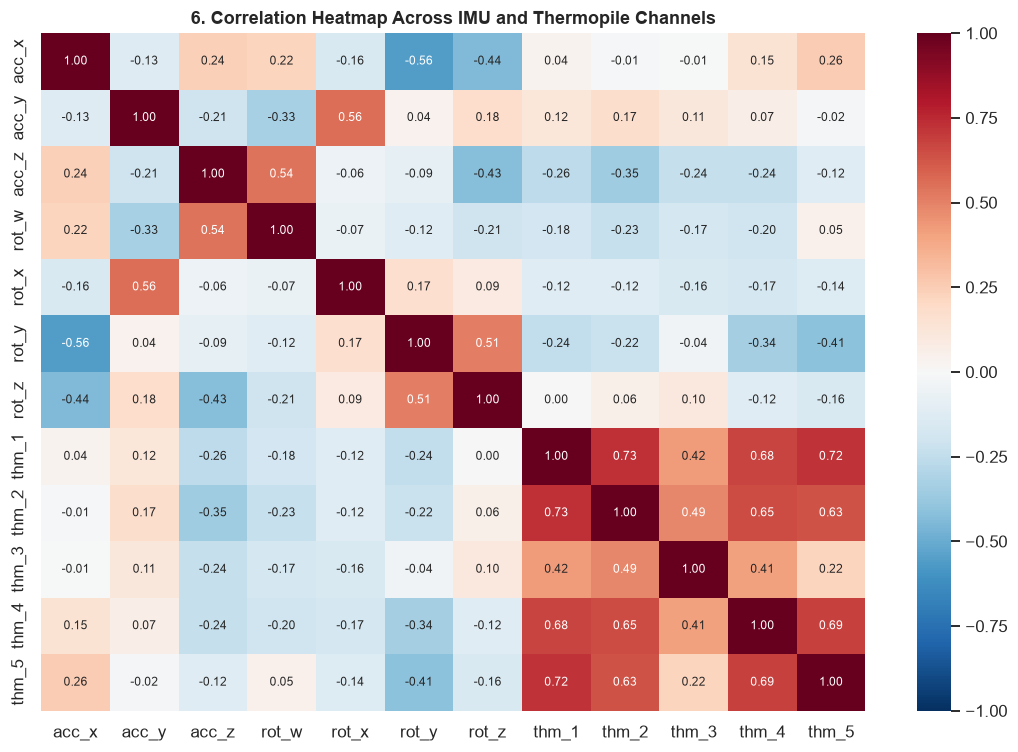

In [8]:
# --- PLOT 6: Correlation Heatmap of Core IMU & Thermopile Channels ---
corr_cols = acc_cols + rot_cols + thm_cols
corr_matrix = train[corr_cols].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr_matrix, cmap='RdBu_r', vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 8})
plt.title("6. Correlation Heatmap Across IMU and Thermopile Channels", fontweight='bold')
plt.tight_layout()
plt.show()

**Interpretation 6 (Inter-Sensor Correlation Structure):**
* **Within-Modality vs. Cross-Modality Independence:** Thermopile channels (`thm_1` through `thm_5`) exhibit strong positive inter-correlation because they measure skin/ambient thermal proximity simultaneously around the wrist. By contrast, accelerometer (`acc_*`), orientation (`rot_*`), and thermal (`thm_*`) modalities show low cross-correlation, confirming that each modality contributes complementary, non-redundant information.

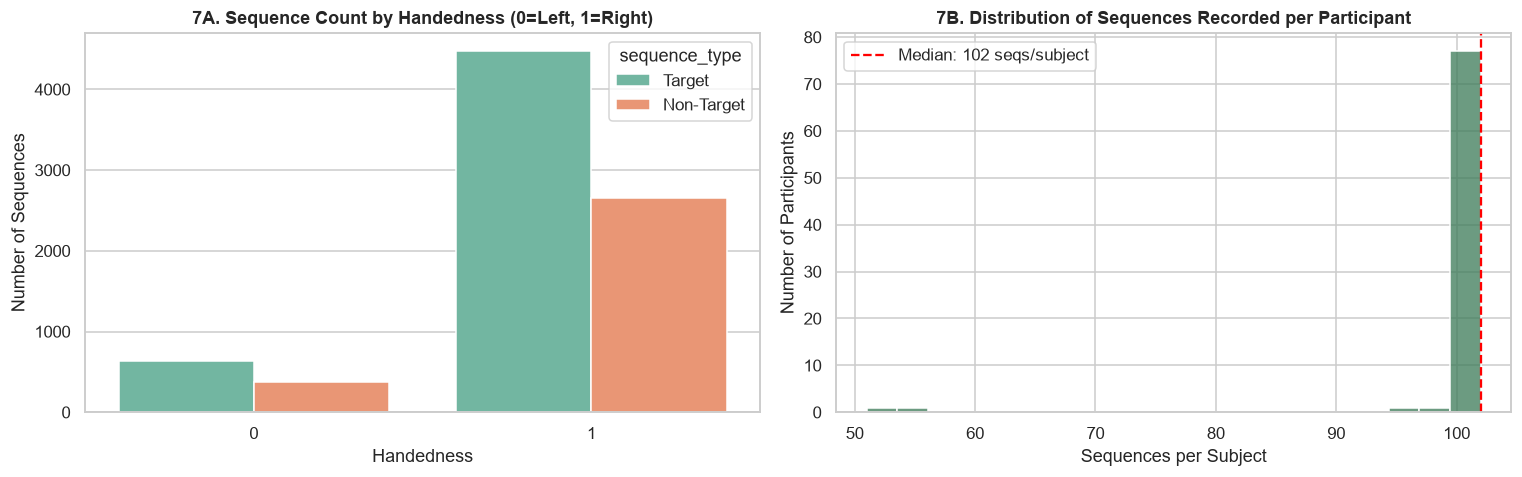

In [15]:
# --- PLOT 7: Participant Demographics & Subject-Level Recording Balance ---
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

if 'handedness' in seq_meta.columns:
    sns.countplot(data=seq_meta, x='handedness', hue='sequence_type', palette='Set2', ax=axes[0])
    axes[0].set_title("7A. Sequence Count by Handedness (0=Left, 1=Right)", fontweight='bold')
    axes[0].set_xlabel("Handedness")
    axes[0].set_ylabel("Number of Sequences")

subj_counts = seq_meta['subject'].value_counts()
sns.histplot(subj_counts, bins=20, color='#3b7a57', ax=axes[1])
axes[1].axvline(subj_counts.median(), color='red', linestyle='--', label=f"Median: {subj_counts.median():.0f} seqs/subject")
axes[1].set_title("7B. Distribution of Sequences Recorded per Participant", fontweight='bold')
axes[1].set_xlabel("Sequences per Subject")
axes[1].set_ylabel("Number of Participants")
axes[1].legend()

plt.tight_layout()
plt.show()

**Interpretation 7 (Demographics and Sequences per Subject):**
* **7A:** Most sequences come from right-handed participants (about 7,100 vs about 1,000), which matches the demographics table (87.7% right-handed). The Target / Non-Target ratio is almost the same in both groups (about 63% / 37%), so handedness does not change the label mix. Still, left-handed participants are few, so the model may perform worse for them.
* **7B:** Almost every subject has about 102 sequences (median = 102). Only a few subjects have fewer (around 50-55). So the data collection is balanced per subject and no single person dominates the dataset.
* **Validation:** Each subject has around 100 sequences with their own movement style. If we split randomly, the same person would be in both train and validation, and the score would look better than it really is. That is why we split by `subject` (`GroupShuffleSplit`).

## 4. Preprocessing
Based on the EDA, we used a simple preprocessing pipeline in `src/data.py`:
1. **Sequence-level aggregation (`extract_sequence_features`):** Each sequence has a different length, so we group by `sequence_id` and compute `mean` and `std` for every sensor column. This gives one row per sequence (data reduction by aggregation, like in the lecture).
2. **Missing values → 0 (`preprocess`):** For IMU-only sequences all `thm_*` / `tof_*` features are NaN. We fill them with 0 instead of the mean/median. If we used the median, an IMU-only sequence would look like a normal full-sensor sequence. With 0 the model can still see that the sensor was missing (thermopile values are normally around 20-40 °C, so 0 is clearly different).
3. **ToF `-1` values:** For the baseline we keep `-1` as it is. We know it means "no object detected" (57.5% of ToF values), so it pulls the mean down. Because of this, `tof_*` mean features should be read as "how often something was close" more than real distance. In Assignment 2 we plan to replace `-1` with NaN and add a "no signal" ratio feature.
4. **No scaling:** Random Forest splits on one feature at a time, so the scale of the features does not change the result.
5. **Encoding:** The only categorical column we use is the target `gesture`, and scikit-learn handles string labels directly.

In [10]:
from src.data import extract_sequence_features, preprocess

df_seq = extract_sequence_features(train, is_train=True)
df_clean = preprocess(df_seq)

print(f"Aggregated sequence feature table: {df_clean.shape[0]:,} sequences x {df_clean.shape[1]} columns")
print(f"Total remaining missing values:    {df_clean.isnull().sum().sum()}")
display(df_clean.head(3))

Aggregated sequence feature table: 8,151 sequences x 667 columns
Total remaining missing values:    0


,sequence_id,subject,gesture,acc_x_mean,acc_x_std,acc_y_mean,acc_y_std,acc_z_mean,acc_z_std,rot_w_mean,...,tof_5_v59_mean,tof_5_v59_std,tof_5_v60_mean,tof_5_v60_std,tof_5_v61_mean,tof_5_v61_std,tof_5_v62_mean,tof_5_v62_std,tof_5_v63_mean,tof_5_v63_std
0,SEQ_000007,SUBJ_059520,Cheek - pinch skin,6.153098,1.334155,3.915570,3.048287,5.577782,2.337517,0.263574,...,53.526316,52.438435,50.473684,51.197484,51.877193,49.119777,55.947368,52.207492,41.192982,46.573843
1,SEQ_000008,SUBJ_020948,Forehead - pull hairline,3.400506,1.087142,5.311179,3.268073,6.581629,2.475402,0.243493,...,-1.000000,0.000000,-1.000000,0.000000,-1.000000,0.000000,-1.000000,0.000000,-1.000000,0.000000
2,SEQ_000013,SUBJ_040282,Cheek - pinch skin,-7.058962,1.295184,2.346182,2.564639,-6.068544,1.330784,0.392208,...,3.698113,34.202780,-1.000000,0.000000,3.603774,33.515978,-1.000000,0.000000,-1.000000,0.000000


## 5. Baseline Model
We train a **Random Forest Classifier** (`src/models.py`) using an 80/20 `GroupShuffleSplit` grouped by `subject` (`random_state=42`). Grouping by `subject` guarantees that the model is evaluated strictly on unseen participants.

Validation Macro F1 Score:        0.4263
Validation Hierarchical F1 Score: 0.6809

--- Per-Class Classification Report ---
                                            precision    recall  f1-score   support

                     Above ear - pull hair       0.56      0.58      0.57       136
                        Cheek - pinch skin       0.41      0.38      0.39       136
                     Drink from bottle/cup       0.78      0.53      0.63        34
                       Eyebrow - pull hair       0.30      0.30      0.30       136
                       Eyelash - pull hair       0.36      0.24      0.29       136
Feel around in tray and pull out an object       0.86      0.88      0.87        34
                  Forehead - pull hairline       0.45      0.51      0.48       136
                        Forehead - scratch       0.46      0.59      0.52       136
                            Glasses on/off       0.60      0.53      0.56        34
                         Neck - pinc

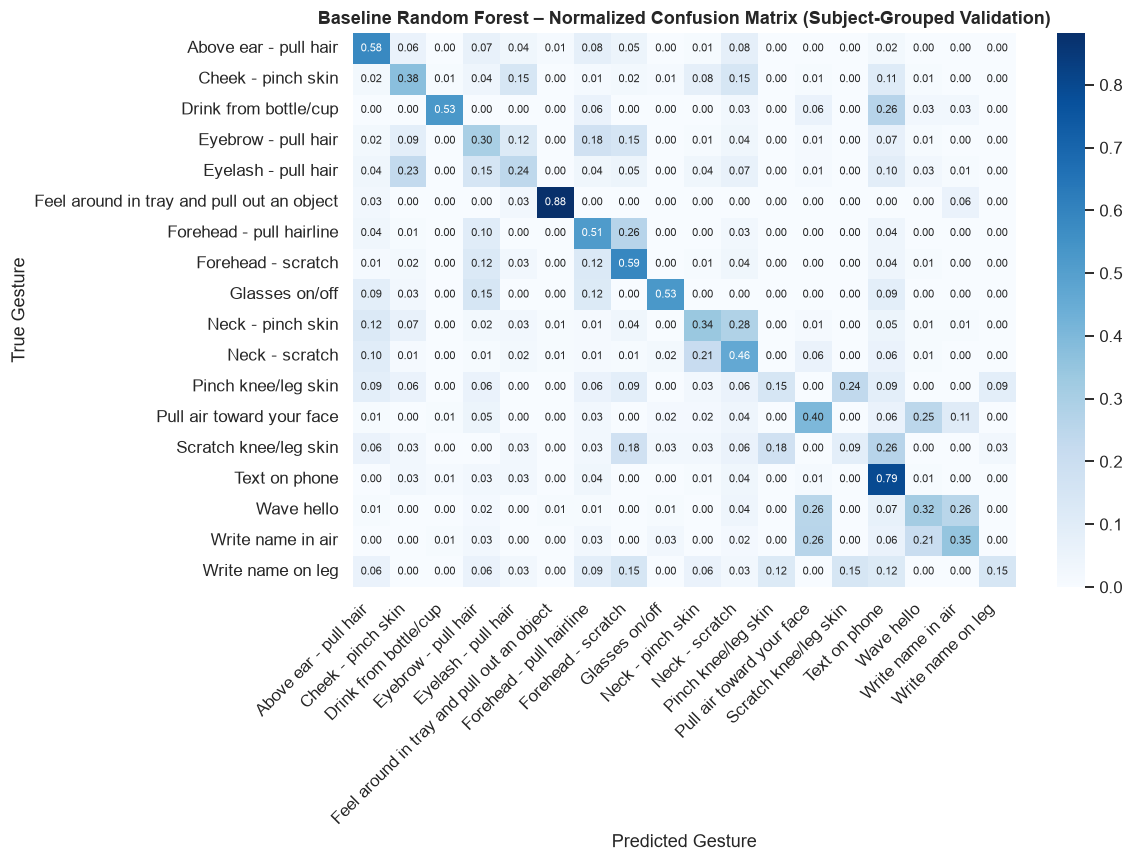

In [11]:
from src.models import train_baseline
from src.utils import compute_hierarchical_f1
from sklearn.metrics import classification_report, confusion_matrix

model, val_macro_f1, X_val, y_val, preds = train_baseline(df_clean)
val_hier_f1 = compute_hierarchical_f1(y_val, preds)

print(f"Validation Macro F1 Score:        {val_macro_f1:.4f}")
print(f"Validation Hierarchical F1 Score: {val_hier_f1:.4f}\n")
print("--- Per-Class Classification Report ---")
print(classification_report(y_val, preds, zero_division=0))

# Visualize Normalized Confusion Matrix
labels = sorted(y_val.unique())
cm = confusion_matrix(y_val, preds, labels=labels, normalize='true')
plt.figure(figsize=(11, 8))
sns.heatmap(cm, xticklabels=labels, yticklabels=labels, cmap='Blues', annot=True, fmt='.2f', annot_kws={'size': 7})
plt.title("Baseline Random Forest – Normalized Confusion Matrix (Subject-Grouped Validation)", fontweight='bold')
plt.xlabel("Predicted Gesture")
plt.ylabel("True Gesture")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 6. Kaggle Submission / Held-Out Evaluation
* **Why held-out:** This is a code competition: submissions must be made from a Kaggle notebook with the evaluation API. Our notebook is written in this repository, so we followed the course rule for closed competitions and evaluated on a held-out split.
* **Our split:** We held out 20% of the data. Instead of a random `train_test_split`, we used `GroupShuffleSplit` by `subject` (`random_state=42`), so no person appears in both train and validation. This is stricter than a random split.
* **Score:** Our Random Forest baseline gets **0.681** on the competition metric (Hierarchical F1) and 0.426 on plain 18-class macro F1.
* **Comparison:** The 1st place team on the private leaderboard scored **0.886**. So we are about 0.2 behind the top solutions, which use deep sequence models (CNN/GRU/Transformer) and much richer features. Their score is on the hidden test set and ours is on a held-out split, so the numbers are not exactly comparable.

---

## 7. Conclusion & Next Steps
### Key Findings
1. BFRB (Target) sequences are the majority (62.7%), but gesture classes are imbalanced (161 to 640 sequences), so macro F1 is the right metric.
2. Only 1.2% of training sequences are IMU-only, but half of the test set is IMU-only, so the model must also work without `thm_*` / `tof_*`.
3. 57.5% of ToF values are `-1` (no signal), which we need to handle better.
4. Simple mean/std features with Random Forest already reach 0.681, mostly because separating BFRB vs non-BFRB is easier than separating similar gestures.

### Next Steps (Assignment 2)
* Replace ToF `-1` with NaN and add "no signal" features.
* Use only the *Performs gesture* phase (from `behavior`) or add phase-based features.
* Add more features (min, max, quantiles, acceleration magnitude) and try gradient boosting.
* Train/check a separate IMU-only model, because half of the test set is IMU-only.
* Try a Kaggle late submission.